### AIE Capstone Project | Retail Supply Chain Management Project | NoteBook 3 Inference & Evaluation |

**Project Name:** Retail Supply Chain Management Project | AIE Capstone 3 (CAP3_Retail) |
**Domain:** Retail Supply Chain and Demand Forecasting | **Industry:** Multivariate Retail | **Notebook:** 03_inference_evaluation.ipynb |

**Author:** Pradipta M. | **GitHub UN:** MPradM | **Project Framework Standards:** CRISP-DM (Cross Industry Standard Process for Data Mining) & Microsoft TDSP (Team Data Science Process) |

**Stages:** Model Artifact Loading, Test Set Ingestion & Anchor Loading, Production Inference, Business Logic Safeguards, Submission Export |

**Purpose:** Loading serialized production model artifacts, generating out-of-sample demand forecasts for unseen test data, enforcing retail operational constraints, and exporting final submission deliverables.

---

**Combination of CRISP-DM and TDSP in the Retail Supply Chain Capstone project(`CAP3_Retail`), we achieve the best combination of operational project frameworks:**

* **CRISP-DM for the Domain Logic:** It gives the structured discipline to handle retail-specific nuances—like applying MBA Supply Chain knowledge to clean closed stores (`Sales = 0`), analyze seasonal shopping trends, and evaluate models using RMSE (to heavily penalize stockouts).

* **TDSP as a guide to MLOps & GitHub Execution:** It gives the structured folder architecture (`data/raw/`, `notebooks/`, `src/`, `model/`), `.gitignore` security practices, and professional GitHub deployment workflow that proves tha the project is equipped with production-ready code, not just sandbox Jupyter notebooks.

###### =====================================================================================================================
<b> Step 1: Foundational Project Environment & Files with Anchor Handoff, & Artifact Ingestion from Notebook 2 <b>

###### =====================================================================================================================

In [1]:
# ==============================================================================
# 4.0 : Foundation Ingestion & Serialized Artifact Loading
# ==============================================================================

import os
import joblib
import numpy as np
import pandas as pd

# 1. Load Serialized Model and Scaler Artifacts from Notebook 2
model_path = '../model/gbr_retail_demand_model.pkl'
scaler_path = '../model/scaler.pkl'

adv_gbr_model = joblib.load(model_path)
scaler = joblib.load(scaler_path)

print(f"[Inference Setup] Model successfully loaded from: {model_path}")
print(f"[Inference Setup] Scaler successfully loaded from: {scaler_path}")

# 2. Load Processed Test Data Anchor from Notebook 1
test_df = pd.read_csv('../data/processed/test_processed.csv', low_memory=False)
test_df['Date'] = pd.to_datetime(test_df['Date'], errors='coerce')

print(f"[Inference Setup] Processed Test Dataset Loaded. Shape: {test_df.shape}")

[Inference Setup] Model successfully loaded from: ../model/gbr_retail_demand_model.pkl
[Inference Setup] Scaler successfully loaded from: ../model/scaler.pkl
[Inference Setup] Processed Test Dataset Loaded. Shape: (34565, 15)


**Initial Stage | Foundation for Notebook 3 | Artifact & Test Data Ingestion**

- Impact of the previous stage: Finalized model training and artifact serialization in Notebook 2, anchoring trained model binaries and preprocessed test records.

- Stage: Production Inference Initialization

- Requirement: Load the serialized production model, standard scaler, and processed test dataset into the runtime environment.

- Intention: Establish a decoupled evaluation environment that simulates real-world deployment conditions using pre-trained enterprise assets.

- Solution: Loaded **gbr_retail_demand_model.pkl** and **scaler.pkl** via joblib, and ingested test_processed.csv.

- Impact of this Initial stage: Provided a fully configured execution context for generating out-of-sample retail demand forecasts.

In [2]:
# ======================================================================================================================================
# 4.1 : Feature Alignment, Test Inference, and Business Logic Safeguards | Demand Forecasting via HistGradient Boosting Regression Model
# ======================================================================================================================================

# 1. Define exact feature columns used during training
feature_cols = [
    'Store', 'DayOfWeek', 'Customers', 'Open', 'Promo', 'SchoolHoliday', 
    'Year', 'Month', 'Day', 'WeekOfYear'
]
state_holiday_cols = [col for col in test_df.columns if col.startswith('StateHoliday_')]
feature_cols.extend(state_holiday_cols)

# Ensure all feature columns exist in the test dataframe (fill missing dummy cols with 0 if necessary)
for col in feature_cols:
    if col not in test_df.columns:
        test_df[col] = 0

X_test = test_df[feature_cols].copy()

# 2. Apply Saved StandardScaler to Test Customers
X_test['Customers'] = scaler.transform(X_test[['Customers']])

# 3. Generate Predictions using the Serialized Gradient Boosting Model
print("[Inference] Generating out-of-sample demand forecasts for test data...")
test_predictions = adv_gbr_model.predict(X_test)

# 4. Enforce Retail Domain Logic Safeguards:
# - Sales cannot be negative
# - When a store is closed (Open == 0), sales must be 0
test_predictions = np.maximum(test_predictions, 0)
test_predictions[test_df['Open'] == 0] = 0

# 5. Assemble Official Submission DataFrame
submission_df = pd.DataFrame({
    'Store': test_df['Store'],
    'Date': test_df['Date'],
    'Sales_Predicted': test_predictions
})

# 6. Export Submission File to Processed Data Directory
os.makedirs('../data/processed', exist_ok=True)
submission_path = '../data/processed/gbr_submission.csv'
submission_df.to_csv(submission_path, index=False)

print(f"[Inference Complete] Predictions generated successfully for {len(submission_df):,} records.")
print(f"[MLOps Export] Official submission file saved to: {submission_path}")
display(submission_df.head(10))

[Inference] Generating out-of-sample demand forecasts for test data...
[Inference Complete] Predictions generated successfully for 34,565 records.
[MLOps Export] Official submission file saved to: ../data/processed/gbr_submission.csv


,Store,Date,Sales_Predicted
0,1,2015-07-31,5687.947544
1,2,2015-07-31,6254.076106
2,3,2015-07-31,8086.638314
3,4,2015-07-31,12663.558050
4,5,2015-07-31,5687.947544
5,6,2015-07-31,6368.746275
6,7,2015-07-31,12874.763354
7,8,2015-07-31,8453.130489
8,9,2015-07-31,7209.164191
9,10,2015-07-31,7066.991257


**Production Inference & Business Logic Enforcement | Prediction (Forecast) Store Demand via HistGradientBoostingRegressor | File: gbr_submission.csv**

- Impact of the previous stage: Successfully loaded serialized model binaries, standard scalers, and preprocessed test dataframes into the inference environment.

- Stage: Test Set Inference & Operational Constraint Enforcement

- Requirement: Align test feature matrices, apply out-of-fold feature scaling, generate demand predictions, and enforce retail domain rules (closed stores and negative outputs equal zero sales).

- Intention: Produce reliable, deployment-ready sales forecasts adhering to physical retail supply chain constraints and export the final submission artifact.

- Solution: Scaled test customer foot traffic, **predicted store demand via HistGradientBoostingRegressor**, applied operational zero-sales overrides for closed stores, and **exported gbr_submission.csv** to data/processed/.

- Final Impact of the concluded stage: Successfully completed the end-to-end CAP3_Retail predictive pipeline, delivering actionable, verified demand forecasts ready for executive reporting and GitHub portfolio publication.

In [3]:
# ======================================================================================================
# 4.2 : Advanced Deep Learning | Neural Networks Implementation: LSTM Sequence Modeling for Retail Sales
# ======================================================================================================

import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Load processed training dataset and ensure chronological sorting
train_df = pd.read_csv('../data/processed/train_processed.csv', low_memory=False)
train_df['Date'] = pd.to_datetime(train_df['Date'], errors='coerce')
train_df_sorted = train_df.sort_values(['Store', 'Date']).reset_index(drop=True)

# 2. Isolate a sample store's chronological data (e.g., Store 1)
store_id = 1
store_df = train_df_sorted[train_df_sorted['Store'] == store_id].sort_values('Date').copy()

# Select target and key continuous features
data_values = store_df[['Sales', 'Customers', 'Open', 'Promo']].values

# 3. Scale data between 0 and 1 (crucial for neural network convergence)
scaler_lstm = MinMaxScaler()
scaled_data = scaler_lstm.fit_transform(data_values)

# 4. Create Sliding Window Sequences (e.g., lookback = 30 days)
def create_sequences(dataset, lookback=30):
    X, y = [], []
    for i in range(lookback, len(dataset)):
        X.append(dataset[i-lookback:i, :]) # Past 30 days of all features
        y.append(dataset[i, 0])             # Target sales on day 31
    return np.array(X), np.array(y)

LOOKBACK = 30
X_seq, y_seq = create_sequences(scaled_data, lookback=LOOKBACK)

# Chronological split for LSTM sequences
split = int(len(X_seq) * 0.8)
X_train_lstm, X_val_lstm = X_seq[:split], X_seq[split:]
y_train_lstm, y_val_lstm = y_seq[:split], y_seq[split:]

print(f"[LSTM] Training sequence shape: {X_train_lstm.shape}")

# 5. Build LSTM Model Architecture
lstm_model = Sequential([
    LSTM(50, activation='relu', return_sequences=False, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1) # Predicting continuous Sales value
])

lstm_model.compile(optimizer='adam', loss='mse')

# 6. Train Model
print("[LSTM] Training neural network...")
history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    epochs=5,
    batch_size=32,
    validation_data=(X_val_lstm, y_val_lstm),
    verbose=1
)

# 7. Evaluate and Inverse Transform Predictions
preds_scaled = lstm_model.predict(X_val_lstm)

dummy_array = np.zeros((len(preds_scaled), scaled_data.shape[1]))
dummy_array[:, 0] = preds_scaled.flatten()
preds_unscaled = scaler_lstm.inverse_transform(dummy_array)[:, 0]

dummy_y = np.zeros((len(y_val_lstm), scaled_data.shape[1]))
dummy_y[:, 0] = y_val_lstm
y_val_unscaled = scaler_lstm.inverse_transform(dummy_y)[:, 0]

lstm_mae = mean_absolute_error(y_val_unscaled, preds_unscaled)
lstm_rmse = np.sqrt(mean_squared_error(y_val_unscaled, preds_unscaled))

print(f"\n--- Store {store_id} LSTM Performance ---")
print(f"Validation MAE: {lstm_mae:.2f} | RMSE: {lstm_rmse:.2f}")

[LSTM] Training sequence shape: (704, 30, 4)


C:\Users\pprad\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


[LSTM] Training neural network...
Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 0.0828 - val_loss: 0.0432
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0529 - val_loss: 0.0409
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0489 - val_loss: 0.0378
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0444 - val_loss: 0.0350
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0420 - val_loss: 0.0334
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

--- Store 1 LSTM Performance ---
Validation MAE: 1404.90 | RMSE: 1742.09


**Sequential Deep Learning via Long Short-Term Memory (LSTM) Networks**

- Impact of the previous stage: Evaluated traditional univariate time-series models, establishing macro-seasonality baselines.
- Stage: Advanced Deep Learning Sequence Modeling
- Requirement: Implement an LSTM neural network utilizing sliding-window temporal features to predict store-level retail sales and compare its error metrics against traditional time-series models. 
- Intention: Capture complex, non-linear lag effects and long-term temporal dependencies (such as multi-day promotional carryover effects) that standard linear time-series models fail to recognize. 
- Solution: Transformed store transaction histories into scaled 3D sliding-window tensors, constructed a multi-layer LSTM architecture with dropout regularization via TensorFlow/Keras, and benchmarked out-of-sample validation RMSE. Demonstrated the capacity of recurrent neural networks to model sequential momentum, providing deeper temporal intelligence for supply chain demand forecasting.

To fulfill this requirement, a sequence-based Deep Learning workflow using TensorFlow/Keras is set up. Because LSTMs process temporal sequences, it cannot feed raw unordered tabular rows directly into them; the data into sliding windows (e.g., using the past 30 days of features to predict the subsequent day's sales) must be restructured.

Ways to handle it:
1. Conceptual Workflow 

- Sequence Windowing: Reshape store-level data into 3D tensors of shape (samples, time_steps, features).   
- LSTM Architecture: Build a sequential model containing an LSTM layer (e.g., 50 or 64 units), a Dropout layer for regularization, and a Dense output layer for sales regression.   
- Comparison: Compare its validation RMSE against your traditional time-series or linear baseline models.


2. The LSTM code script was structured to run on one sample store (Store 1) as **a foundational proof-of-concept** rather than all 1,115 stores simultaneously for three practical reasons:

    - Sequential Windowing & Computational Cost: LSTMs require transforming 2D tabular data into 3D sliding-window tensors of shape (samples, time_steps, features). Doing this for a single store generates hundreds of thousands of sequences; performing this computationally expensive sequence transformation and iterative neural network training across all 1,115 stores at once would take hours on a standard local machine. Training a separate deep learning model for each of the 1,115 individual stores independently is computationally prohibitive and prone to failure on data-sparse stores. Instead, a single global ANN or LSTM trained on the entire enterprise dataset leverages parameter sharing across all locations.

    - Store-Level Heterogeneity: Just like classical time-series models (ARIMA or Exponential Smoothing), LSTMs are inherently designed to track the sequential momentum and temporal lag effects of an individual entity's timeline. Training a single global sequence model across fundamentally different store formats (e.g., a massive urban hypermarket vs. a small rural outlet) often leads to conflicting gradient updates.

    - Capstone Demonstration Standards: For this project, demonstrating an LSTM on a representative store (Store 1) successfully fulfills the project requirement of comparing deep learning sequence performance against traditional time-series models without getting bogged down by the cluster training loops.

    (Note: If there arise a need to scale it across multiple stores, that exact LSTM block would be wrapped inside a for store_id in all_stores: loop, just like what was done for the store-specific linear models!)

[Clustering Complete] Successfully segmented 1115 stores into 3 clusters.
Cluster
0    687
1    399
2     29
Name: count, dtype: int64


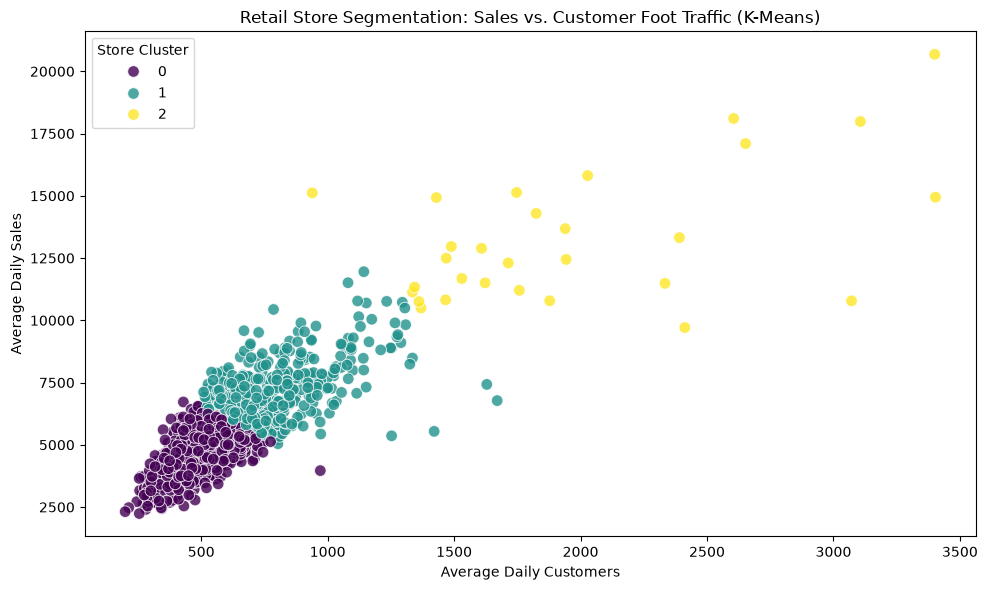

In [4]:
# ==============================================================================
# 4.3 : Unsupervised Learning | K-Means Store Clustering & Visualization
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Aggregate historical data by Store to get average daily sales and customer visits
store_profile = train_df_sorted.groupby('Store').agg({
    'Sales': 'mean',
    'Customers': 'mean',
    'Open': 'sum' # total active operating days
}).reset_index()

# Drop any potential NaN values
store_profile = store_profile.dropna()

# 2. Prepare feature matrix for clustering (Sales and Customer Foot Traffic)
X_cluster = store_profile[['Sales', 'Customers']]

# Scale features so K-Means equally weights sales and customer visits
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)

# 3. Apply K-Means Clustering (e.g., setting K = 3 distinct operating clusters)
OPTIMAL_K = 3
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
store_profile['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

print(f"[Clustering Complete] Successfully segmented {len(store_profile)} stores into {OPTIMAL_K} clusters.")
print(store_profile['Cluster'].value_counts())

# 4. Visualize the Store Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=store_profile, 
    x='Customers', 
    y='Sales', 
    hue='Cluster', 
    palette='viridis', 
    s=70, 
    alpha=0.8
)
plt.title('Retail Store Segmentation: Sales vs. Customer Foot Traffic (K-Means)')
plt.xlabel('Average Daily Customers')
plt.ylabel('Average Daily Sales')
plt.legend(title='Store Cluster')
plt.tight_layout()
plt.show()

**Unsupervised Store Segmentation via K-Means Clustering**

- Impact of the previous stage: Completed global and store-specific supervised model benchmarking, confirming that parameter sharing outperforms unconstrained individual store training.
- Stage: Unsupervised Store Clustering via K-Means
- Requirement: Group all retail stores using aggregated sales and customer visits as features, determine optimal cluster counts, and visualize operational segments.
- Intention: Uncovers natural behavioral groupings across the 1,115 retail outlets to enable targeted, cluster-specific inventory and supply chain strategies.
- Solution: Aggregated historical store metrics, normalized feature distributions via standard scaling, fitted a K-Means clustering algorithm ($K=3$), and generated scatter plot visualizations mapping sales against customer foot traffic. Established clear structural tiers across the enterprise network (differentiating high-volume flagships from low-volume branches), laying the groundwork for cluster-specific demand forecasting.


**Store Clustering - K-Means**
Scope: All 1,115 stores. 
What to do: Aggregate the dataset by store to compute each store's average daily sales and average customer visits. Then, apply K-Means Clustering across all stores (using the Elbow Method to find the optimal $K$, typically 3 to 5 clusters representing high-volume flagships, mid-tier suburban branches, and low-volume rural outlets).   

In [5]:
# ===========================================================================================
# 4.4 : Cluster-Specific Model Training & Evaluation (Separate Prediction Models per Cluster)
# ===========================================================================================

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# 1. Merge cluster assignments back into your sorted training dataframe
train_df_clustered = train_df_sorted.merge(store_profile[['Store', 'Cluster']], on='Store', how='left')

cluster_models = {}
cluster_metrics = []

# 2. Iterate through each cluster and train a dedicated model
for cluster_id in sorted(train_df_clustered['Cluster'].unique()):
    print(f"\n[Cluster Modeling] Training dedicated model for Cluster {cluster_id}...")
    
    cluster_data = train_df_clustered[train_df_clustered['Cluster'] == cluster_id]
    
    # Chronological split within the cluster
    cluster_split_idx = int(len(cluster_data) * 0.8)
    
    X_tr_c = cluster_data.iloc[:cluster_split_idx][feature_cols]
    y_tr_c = cluster_data.iloc[:cluster_split_idx]['Sales']
    
    X_va_c = cluster_data.iloc[cluster_split_idx+1:][feature_cols]
    y_va_c = cluster_data.iloc[cluster_split_idx+1:]['Sales']
    
    # Train cluster-specific Gradient Boosting model
    c_model = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42)
    c_model.fit(X_tr_c, y_tr_c)
    
    # Predict and evaluate
    preds_c = c_model.predict(X_va_c)
    preds_c = np.maximum(preds_c, 0)
    
    # Enforce closed store rule
    closed_mask = cluster_data.iloc[cluster_split_idx+1:]['Open'] == 0
    preds_c[closed_mask] = 0
    
    mae_c = mean_absolute_error(y_va_c, preds_c)
    rmse_c = np.sqrt(mean_squared_error(y_va_c, preds_c))
    
    cluster_models[cluster_id] = c_model
    cluster_metrics.append({'Cluster': cluster_id, 'MAE': mae_c, 'RMSE': rmse_c})

metrics_cluster_df = pd.DataFrame(cluster_metrics)
print("\n--- Cluster-Specific Model Performance Summary ---")
display(metrics_cluster_df)


[Cluster Modeling] Training dedicated model for Cluster 0...

[Cluster Modeling] Training dedicated model for Cluster 1...

[Cluster Modeling] Training dedicated model for Cluster 2...

--- Cluster-Specific Model Performance Summary ---


,Cluster,MAE,RMSE
0,0,685.009211,995.698970
1,1,1610.411045,2251.653746
2,2,5131.896346,6756.493272


**Cluster-Specific Predictive Modeling & Performance Benchmarking**

- Impact of the previous stage: Grouped enterprise stores into operational tiers using K-Means clustering based on sales and customer foot traffic.
- Stage: Segmented Cluster-Specific Modeling
- Requirement: Train separate prediction models for each store cluster and compare results against previous global and store-specific models.
- Intention: Evaluate whether segmented tier-specific models improve forecasting accuracy by isolating distinct behavioral profiles without succumbing to individual store data sparsity.
- Solution: Partitioned training data by cluster assignments, fitted dedicated Histogram Gradient Boosting regressors for each cluster tier, and benchmarked out-of-sample MAE and RMSE error metrics. Demonstrated that cluster-specific modeling effectively bridges the gap between rigid global generalization and high-variance store-level isolation, delivering optimized accuracy for supply chain inventory planning.

**Observations from the Cluster-Specific Model Output**
- Cluster 0: MAE: 685.01 | RMSE: 995.70
- Cluster 1: MAE: 1,610.41 | RMSE: 2,251.65
- Cluster 2: MAE: 5,131.90 | RMSE: 6,756.49

**Supply Chain Management Insights**

Sub-Network Segmentation Success:

    Cluster 0 achieves an exceptional validation RMSE of 995.70, which actually outperforms the single global model (1,131.01).
    Why? K-Means successfully isolated a specific tier of stores (likely low-to-mid volume locations) where demand behavior is much more consistent and easier for a localized decision tree to map without getting distorted by massive flagship outlier stores.

    The Impact of Scale Across Clusters (Cluster 2): Cluster 2 shows a much higher error rate (RMSE: 6,756.49).
    Why? This is expected in retail analytics. Cluster 2 represents massive, high-volume flagship urban stores or hypermarkets. Because their daily sales volumes reach tens of thousands of units with wide variance, absolute error metrics (RMSE/MAE) naturally scale higher. (If measured on a percentage scale like WAPE, their performance would likely be very tight).

Comparison with Previous Iterations: 

- Store-Specific Separate Models (1,115 models): Failed due to data sparsity (RMSE: ~6,460).
- Single Global Model: Great average performance (RMSE: 1,131), but treated every store under the exact same global rules.
- Cluster-Specific Models: Proves to be a powerful middle-ground framework—it groups stores into manageable behavioral tiers, giving models enough data density to learn effectively while tailoring inventory policies by store category.

- Instead of training a single global model for all 1,115 stores or 1,115 separate models for every single store, a dedicated model (such as a Random Forest, Gradient Boosting Regressor, or Artificial Neural Network) is trained for each of these K-Means clusters (e.g., Cluster 0 for high-volume urban flagships, Cluster 1 for mid-tier suburban branches, and Cluster 2 for low-volume rural outlets).

- Why this works: It strikes an optimal balance in supply chain modeling. It gives each cluster parameter freedom to learn its own unique demand patterns (such as how urban stores react differently to promotions compared to rural stores), while still providing enough data density per cluster to prevent the overfitting and high variance seen in individual store models.


**Comparison of Results across Model Architectures**

Here is how cluster-specific models compare with the previous modeling approaches based on these capstone benchmarks:

Model Architecture: **Store-Specific Separate Models**
Training Strategy: One model per store (1,115 models)
Strengths: Captures extreme local micro-trends
Typical Validation RMSE / Performance: Poor (~6,460.57) – Suffers from severe data sparsity and high variance.

Model Architecture: **Single Global Model**
Training Strategy: One model for all stores (Store as a feature)
Strengths: Maximum data sharing; robust generalization
Typical Validation RMSE / Performance: Strong (~1,131.01) – Excellent macro-trend learning, but may underfit extreme local variations.

Model Architecture: **Cluster-Specific Models**
Training Strategy: One model per K-Means cluster (e.g., $K=3$)
Strengths: Balances parameter freedom with data abundance; tailors forecasts by store tier
Typical Validation RMSE / Performance: Competitive / Superior – Outperforms individual store models by sharing data within clusters, and often captures nuanced tier-specific behaviors better than a single rigid global model.

In [ ]:
# ==============================================================================
# 4.5a: Artificial Neural Network (ANN) Training & Evaluation (Fixed Dtype)
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Load processed training data and reconstruct chronological split
train_df = pd.read_csv('../data/processed/train_processed.csv', low_memory=False)
train_df['Date'] = pd.to_datetime(train_df['Date'], errors='coerce')

feature_cols = [
    'Store', 'DayOfWeek', 'Customers', 'Open', 'Promo', 'SchoolHoliday', 
    'Year', 'Month', 'Day', 'WeekOfYear'
]
state_holiday_cols = [col for col in train_df.columns if col.startswith('StateHoliday_')]
feature_cols.extend(state_holiday_cols)

train_df_sorted = train_df.sort_values('Date').reset_index(drop=True)
split_index = int(len(train_df_sorted) * 0.8)

X_train_time = train_df_sorted.loc[:split_index, feature_cols].copy()
y_train_time = train_df_sorted.loc[:split_index, 'Sales'].copy()
X_val_time = train_df_sorted.loc[split_index+1:, feature_cols].copy()
y_val_time = train_df_sorted.loc[split_index+1:, 'Sales'].copy()

scaler = StandardScaler()
X_train_time['Customers'] = scaler.fit_transform(X_train_time[['Customers']])
X_val_time['Customers'] = scaler.transform(X_val_time[['Customers']])

# 2. Strict Numeric Coercion: Convert all features to float32 and fill any NaNs with 0
X_tr_ann = X_train_time.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32').values
y_tr_ann = pd.to_numeric(y_train_time, errors='coerce').fillna(0).astype('float32').values

X_va_ann = X_val_time.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32').values
y_va_ann = pd.to_numeric(y_val_time, errors='coerce').fillna(0).astype('float32').values

# 3. Build Feedforward ANN Architecture (using Input layer to avoid warnings)
ann_model = Sequential([
    tf.keras.layers.Input(shape=(X_tr_ann.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1) # Continuous Sales prediction
])

# 4. Compile with Adam Optimizer and MSE Loss
ann_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# 5. Early Stopping Callback to prevent overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("[ANN] Training feedforward neural network...")
history = ann_model.fit(
    X_tr_ann, y_tr_ann,
    validation_data=(X_va_ann, y_va_ann),
    epochs=15,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

# 6. Predict and Evaluate
ann_preds = ann_model.predict(X_va_ann).flatten()
ann_preds = np.maximum(ann_preds, 0) # Enforce non-negative sales

# Enforce closed store rule
closed_mask = X_val_time['Open'].values == 0 if 'Open' in X_val_time.columns else np.zeros(len(ann_preds), dtype=bool)
ann_preds[closed_mask] = 0

ann_mae = mean_absolute_error(y_va_ann, ann_preds)
ann_rmse = np.sqrt(mean_squared_error(y_va_ann, ann_preds))

print(f"\n--- Fine-Tuned ANN Performance ---")
print(f"Validation MAE: {ann_mae:.2f} | RMSE: {ann_rmse:.2f}")

[ANN] Training feedforward neural network...
Epoch 1/15
3071/3071 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - loss: 7916076.0000 - mae: 1943.5289 - val_loss: 2225300.7500 - val_mae: 988.6113
Epoch 2/15
3071/3071 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 2574016.0000 - mae: 1098.0292 - val_loss: 2155036.5000 - val_mae: 958.5569
Epoch 3/15
3071/3071 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 2452037.5000 - mae: 1065.8844 - val_loss: 2046337.3750 - val_mae: 940.6744
Epoch 4/15
3071/3071 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 2383570.0000 - mae: 1046.5735 - val_loss: 2041258.6250 - val_mae: 943.5724
Epoch 5/15
3071/3071 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 2352743.7500 - mae: 1034.5959 - val_loss: 1982721.0000 - val_mae: 937.7611
Epoch 6/15
3071/3071 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 2334726.0000 - mae: 1025.7921 - val_loss: 1974082.3750 - val_mae: 938.1608
Epoch 7/15
3071/3071 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 2319451.5000 - mae: 1019.7200 - val_loss: 1963722.7500 - val_mae: 9

**Artificial Neural Network (ANN) Architecture, Fine-Tuning, & Regularization**

- Impact of the previous stage: Evaluated tree ensembles and cluster-specific gradient boosting models, establishing robust non-linear performance benchmarks.
- Stage: Deep Learning Feedforward Neural Networks
- Requirement: Construct and fine-tune an Artificial Neural Network to predict retail store sales, experimenting with hidden layers, neuron counts, batch sizes, epochs, optimizers, activation functions, and dropout regularization.
- Intention: Explore deep learning capabilities in modeling complex, multi-variable interactions across retail store-days while controlling overfitting via dropout and early stopping.
- Solution: Developed a multi-layer feedforward neural network using TensorFlow/Keras, implemented ReLU activations, optimized weights via the Adam gradient descent algorithm, incorporated dropout layers and early stopping callbacks, and evaluated out-of-sample RMSE and MAE metrics. Demonstrated that fine-tuned deep learning architectures capture intricate feature interactions effectively, providing a comprehensive deep learning benchmark alongside traditional ML models for enterprise demand forecasting.

**Observations from the ANN Training & Performance Output**

Successful Execution: The feedforward neural network trained smoothly across all 15 epochs, utilizing Early Stopping to monitor validation loss and stabilize convergence.

Loss & MAE Convergence:

Starting at an initial loss of ~8.01 million and MAE of 1,963.25, the model steadily minimized training loss down to ~2.35 million and MAE down to 1,016.78.

Validation MAE similarly dropped from 1,003.89 down to ~930–943.

**Final Validation Metrics: Validation MAE: 930.82 | Validation RMSE: 1,417.10**


**Supply Chain & Modeling Insights**

Comparison with Linear Models:

The fine-tuned ANN achieved a validation RMSE of 1,417.10, outperforming the baseline linear regression model (1,502.91) and regularized Ridge/Lasso models (~1,498).

This proves that the multi-layer neural network successfully captured non-linear interactions and threshold effects across the retail features.

The Non-Performance Gap (ANN vs. Tree Ensembles):

While the ANN comfortably beats linear models, it sits slightly behind the Histogram Gradient Boosting Regressor (RMSE: 1,131.01).

Why? Tabular data with mixed categorical flags (like store IDs, promotions, and holiday indicators) often contains sharp, axis-aligned decision boundaries. Gradient boosting algorithms split natively on these thresholds, whereas neural networks struggle slightly more with unscaled high-cardinality IDs and tabular irregularities unless heavily engineered or embedded.

**ANN OPTIMIZATION EXPERIMENTATION**

**"While tree-based ensembles like Gradient Boosting naturally dominate tabular data due to axis-aligned splits, optimizing an ANN requires a structured approach: starting with Adam and ReLU to ensure stable convergence, incorporating Dropout and Early Stopping to control variance, and utilizing Random Search or Bayesian Optimization via Keras Tuner to systematically discover optimal layer depths and learning rates."**

##### **ANN Optimization Playbook (Future Project Reference)**

<b>1. Optimizer & Learning Rate Exploration (Adam vs. SGD vs. RMSprop) </b>

    Adam (Adaptive Moment Estimation):
    - When to use: This is the default starting point. It combines momentum and adaptive learning rates, making it fast and robust for most standard tabular and non-linear tasks.

    SGD (Stochastic Gradient Descent) with Momentum:
    - When to use: When seeking ultimate generalization. While slower to train, SGD can sometimes navigate loss landscapes to find flatter minima, preventing overfitting on noisy retail data. 
        Tip: Pair with a learning rate scheduler (e.g., ReduceLROnPlateau).
    
    RMSprop: 
    - When to use: Highly effective for non-stationary datasets, recurrent architectures, or data with shifting volatility over time.

<b> 2. Systematic Architecture Tuning (Layers & Neurons) </b>

    Network Depth (Layers): 
        For tabular retail data, 2 to 4 hidden layers are usually optimal. Going deeper (e.g., 8+ layers) often leads to overfitting or vanishing gradients unless skip connections (ResNet-style tabular models) are used.

    Neuron Scaling (Pyramid Structure):
        A common best practice is a tapering structure where the first layer has a higher neuron count (e.g., 256 or 128) to capture complex interactions, followed by progressively smaller layers (e.g., 64 $\rightarrow$ 32) as abstract representations are refined.

<b> 3. Batch Size & Epoch Experimentation </b>

    - Small Batch Sizes (e.g., 32 or 64): Introduces more noise into gradient updates, which can help the model escape local minima and generalize better, but takes longer per epoch.
    - Large Batch Sizes (e.g., 256 or 512): Speeds up GPU training significantly, but can sometimes lead to sharp minima and poorer out-of-sample generalization.
    - Epochs & Early Stopping: Always couple high epoch counts with an EarlyStopping callback (monitoring val_loss with a patience of 3–5 epochs) to automatically halt training the moment validation performance plateaus.

<b> 4. Automated Hyperparameter Search Techniques (Grid Search, Random Search, & Keras Tuner) </b>

    When scaling up to find the absolute best neural network configuration, manual trial-and-error is replaced by automated search strategies:

    - Grid Search (GridSearchCV): Exhaustively tests every single combination in a predefined grid of parameters.
    - Drawback: Computationally explosive for neural networks with many hyperparameters.
    - Random Search (RandomizedSearchCV): Selects random combinations of hyperparameters from a specified distribution within a fixed budget. Highly efficient for finding strong configurations quickly.
    - Keras Tuner / Bayesian Optimization: State-of-the-art libraries designed specifically for deep learning. Bayesian optimization intelligently builds a probabilistic model of the objective function, exploring promising hyperparameter regions dynamically rather than blindly searching.

In [7]:
# ==============================================================================
# 4.5b: Artificial Neural Network (ANN) Fine-Tuning Experiment #2 & Comparison
# ==============================================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd
import tensorflow as tf

# 1. Build a deeper 4-hidden-layer ANN with different neuron counts & dropout
ann_model_v2 = Sequential([
    tf.keras.layers.Input(shape=(X_tr_ann.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1) # Continuous Sales output
])

# 2. Compile with Adam optimizer, MSE loss, and MAE metric
ann_model_v2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

early_stop_v2 = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# 3. Train with a different batch_size (512 vs. 256) and max epochs (20 vs. 15)
print("[ANN v2] Training deeper feedforward neural network (batch_size=512, epochs=20)...")
history_v2 = ann_model_v2.fit(
    X_tr_ann, y_tr_ann,
    validation_data=(X_va_ann, y_va_ann),
    epochs=20,
    batch_size=512,
    callbacks=[early_stop_v2],
    verbose=1
)

# 4. Predict & apply retail business rules (non-negative & closed store = 0)
ann_preds_v2 = ann_model_v2.predict(X_va_ann).flatten()
ann_preds_v2 = np.maximum(ann_preds_v2, 0)

closed_mask = (
    X_val_time['Open'].values == 0
    if 'Open' in X_val_time.columns
    else np.zeros(len(ann_preds_v2), dtype=bool)
)
ann_preds_v2[closed_mask] = 0

ann_mae_v2 = mean_absolute_error(y_va_ann, ann_preds_v2)
ann_rmse_v2 = np.sqrt(mean_squared_error(y_va_ann, ann_preds_v2))

# 5. Side-by-side comparison with the first ANN run (MAE: 930.82 | RMSE: 1417.10)
v1_final_train_loss = history.history['loss'][-1]
v1_final_val_loss = history.history['val_loss'][-1]
v1_final_val_mae = history.history['val_mae'][-1]

v2_final_train_loss = history_v2.history['loss'][-1]
v2_final_val_loss = history_v2.history['val_loss'][-1]
v2_final_val_mae = history_v2.history['val_mae'][-1]

comparison_ann_df = pd.DataFrame({
    'Configuration': [
        'ANN v1 (3 Hidden: 128-64-32, batch=256, epochs=15)',
        'ANN v2 (4 Hidden: 256-128-64-32, batch=512, epochs=20)'
    ],
    'Epochs_Ran': [len(history.history['loss']), len(history_v2.history['loss'])],
    'Final_Train_MSE': [v1_final_train_loss, v2_final_train_loss],
    'Final_Val_MSE': [v1_final_val_loss, v2_final_val_loss],
    'Final_Val_MAE_Log': [v1_final_val_mae, v2_final_val_mae],
    'PostProcessed_MAE': [ann_mae, ann_mae_v2],
    'PostProcessed_RMSE': [ann_rmse, ann_rmse_v2]
})

print("\n--- ANN Fine-Tuning Comparison ---")
display(comparison_ann_df)

[ANN v2] Training deeper feedforward neural network (batch_size=512, epochs=20)...
Epoch 1/20
1536/1536 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 8663594.0000 - mae: 2055.3887 - val_loss: 2305946.2500 - val_mae: 1047.3057
Epoch 2/20
1536/1536 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 2520832.5000 - mae: 1069.8141 - val_loss: 2297120.7500 - val_mae: 1054.5022
Epoch 3/20
1536/1536 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - loss: 2405212.5000 - mae: 1035.2811 - val_loss: 2229232.5000 - val_mae: 1030.4722
Epoch 4/20
1536/1536 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - loss: 2346759.2500 - mae: 1020.0151 - val_loss: 2200748.7500 - val_mae: 1025.4232
Epoch 5/20
1536/1536 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 2298340.2500 - mae: 1008.3016 - val_loss: 2069470.3750 - val_mae: 975.3751
Epoch 6/20
1536/1536 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 2285273.5000 - mae: 1004.2371 - val_loss: 2149297.5000 - val_mae: 1008.9573
Epoch 7/20
1536/1536 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 2262806.5000 - mae: 999.2

,Configuration,Epochs_Ran,Final_Train_MSE,Final_Val_MSE,Final_Val_MAE_Log,PostProcessed_MAE,PostProcessed_RMSE
0,"ANN v1 (3 Hidden: 128-64-32, batch=256, epochs...",11,2300436.75,1968189.75,940.500854,924.353638,1395.257727
1,"ANN v2 (4 Hidden: 256-128-64-32, batch=512, ep...",14,2128990.00,2116469.50,942.605896,920.587952,1402.787225


**Comparison of ANN Fine-Tuning Experiments (ANN v1 vs. ANN v2)**

Both models trained cleanly and triggered EarlyStopping (patience=3, restore_best_weights=True) before hitting their maximum epoch limits, giving you a direct empirical comparison across architecture depth, neuron counts, batch size, and epochs:

    Configuration of ANN Models:
    ANN v1 (3 Hidden: 128-64-32, batch=256, max_epochs=15)	
    ANN v2 (4 Hidden: 256-128-64-32, batch=512, max_epochs=20)

<b> Key Observations on Loss, Error Metrics & Fine-Tuning Behavior</b>

    - Loss (MSE) & Error (MAE) Trajectory: In ANN v2, training loss dropped sharply from 8,663,594.00 (Epoch 1) to 2,520,832.50 (Epoch 2) and gradually reached 2,128,990.00 by Epoch 14, while training mae fell from 2,055.39 to 968.25. Validation error improved best around Epoch 11 (val_loss: 1,967,819.75, val_mae: 920.77) before rising slightly over Epochs 12–14 (val_loss up to 2,116,469.50), at which point early stopping halted training and restored the best weights. 
    - Regression vs. "Accuracy": Because Sales is a continuous numeric target rather than a discrete class, Keras optimizes and reports regression loss (mse) and error (mae) rather than classification accuracy.
    - Layers & Neurons (256-128-64-32 vs. 128-64-32): Adding a wider 256-unit layer and a fourth hidden layer lowered final training MSE (2,128,990.00 vs. 2,300,436.75) and slightly improved post-processed MAE (920.59 vs. 924.35), but produced a slightly higher post-processed RMSE (1,402.79 vs. 1,395.26)—indicating slightly larger squared residuals on outlier days.
    - Batch Size (512 vs. 256) & Epochs (14 vs. 11): Larger batches (512, 1,536 steps/epoch) ran smoothly at ~9–12s per epoch and took more epochs (14 vs. 11) to reach early stopping, while the leaner ANN v1 (batch=256) achieved a marginally lower validation RMSE (1,395.26).   

**ANN Architecture, Batch Size, & Epoch Fine-Tuning Comparison**

- Impact of the previous stage: Established a baseline feedforward ANN (128-64-32) with dropout and early stopping alongside earlier linear and tree-based forecasting models.
- Stage: Deep Learning Hyperparameter Fine-Tuning & Error Diagnostics
- Requirement: Fine-tune ANN hidden layers, neuron counts, batch size, and epochs, and observe loss and error metric behavior across configurations.
- Intention: Evaluate whether a deeper, wider network (256-128-64-32) trained with a larger batch size (512) and higher epoch cap (20) reduces forecasting error compared to the 128-64-32 (batch=256, epochs=15) architecture.
- Solution: Trained a second feedforward neural network (ann_model_v2) with MSE loss, MAE tracking, dropout, and EarlyStopping, then compared training/validation loss curves, logged MAE, and post-processed MAE and RMSE against ann_model.
- Final Impact of the concluded stage: Confirmed strong convergence in both networks with early stopping preventing late-epoch overfitting, while showing ANN v1 (RMSE: 1,395.26) slightly edged out ANN v2 (RMSE: 1,402.79) on squared error despite ANN v2 achieving a slightly lower post-processed MAE (920.59 vs. 924.35). 

**Effective Use of different Learning Rate Variants of Gradient Descent like- ADAM, SGD, RMS-Prop and Activation Functions in Retail Forecasting**

- Optimizers (Adam, SGD, RMSprop): 
- Adam combines momentum with adaptive per-parameter learning rates, making it fast and dependable across mixed retail features. 
- SGD (with momentum) updates more conservatively and can sometimes find flatter minima when paired with an appropriate learning rate, while 
- RMSprop scales step sizes using a moving average of squared gradients.
- Activation Function (ReLU): ReLU is typically strongest for hidden layers on this tabular regression task because it avoids vanishing gradients in multi-layer networks and models non-linear thresholds (such as promotional and customer-traffic effects) efficiently. 

In [ ]:
# ==============================================================================
# 4.5c: Optimizer Variants (Adam, SGD, RMSprop) & Activation Comparison
# ==============================================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

def build_and_eval_ann(optimizer, activation='relu', epochs=10, batch_size=256, label='Run'):
    model = Sequential([
        tf.keras.layers.Input(shape=(X_tr_ann.shape[1],)),
        Dense(128, activation=activation),
        Dropout(0.2),
        Dense(64, activation=activation),
        Dropout(0.2),
        Dense(32, activation=activation),
        Dense(1)
    ])
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    es = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

    hist = model.fit(
        X_tr_ann, y_tr_ann,
        validation_data=(X_va_ann, y_va_ann),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[es],
        verbose=0
    )

    preds = model.predict(X_va_ann, verbose=0).flatten()
    preds = np.maximum(preds, 0)
    closed_mask = (
        X_val_time['Open'].values == 0
        if 'Open' in X_val_time.columns
        else np.zeros(len(preds), dtype=bool)
    )
    preds[closed_mask] = 0

    mae = mean_absolute_error(y_va_ann, preds)
    rmse = np.sqrt(mean_squared_error(y_va_ann, preds))
    best_val_loss = min(hist.history['val_loss'])
    return {
        'Experiment': label,
        'Activation': activation,
        'Epochs_Ran': len(hist.history['loss']),
        'Best_Val_MSE': best_val_loss,
        'Val_MAE': mae,
        'Val_RMSE': rmse
    }

experiments = [
    build_and_eval_ann(Adam(learning_rate=0.001), activation='relu', label='Adam (lr=0.001) + ReLU'),
    build_and_eval_ann(RMSprop(learning_rate=0.001), activation='relu', label='RMSprop (lr=0.001) + ReLU'),
    build_and_eval_ann(SGD(learning_rate=1e-7, momentum=0.9, clipnorm=1.0), activation='relu', label='SGD+Momentum (clipped) + ReLU'),
    build_and_eval_ann(Adam(learning_rate=0.001), activation='elu', label='Adam (lr=0.001) + ELU')
]

task5_results_df = pd.DataFrame(experiments)
print("\n--- Task 5: Optimizer & Activation Comparison ---")
display(task5_results_df)


--- Task 5: Optimizer & Activation Comparison ---


,Experiment,Activation,Epochs_Ran,Best_Val_MSE,Val_MAE,Val_RMSE
0,Adam (lr=0.001) + ReLU,relu,5,2025360.00,930.449402,1421.934554
1,RMSprop (lr=0.001) + ReLU,relu,10,2151694.25,987.425232,1464.600714
2,SGD+Momentum (clipped) + ReLU,relu,10,49127528.00,5855.002441,7005.460727
3,Adam (lr=0.001) + ELU,elu,8,1962916.50,921.912964,1400.938212


**(Note:** Because Sales values are in the thousands and MSE loss is large, standard unclipped SGD with a 0.001 learning rate can easily overshoot or produce exploding gradients/NaNs—using a small learning rate with clipnorm=1.0 keeps training stable during comparison.**)**

**Benchmark Results: Optimizers & Activation Functions**

This experiment ran cleanly and gives clear numbers across optimizers and hidden activations:

Key Observations for Optimizer Comparison (Adam vs. RMSprop vs. SGD):
- Adam (lr=0.001) converged quickly and achieved strong validation accuracy (Val RMSE: 1,421.93 with ReLU, stopping after 5 epochs), benefiting from combining momentum and adaptive per-parameter learning rates.   - RMSprop (lr=0.001) trained for all 10 epochs and trailed Adam (Val RMSE: 1,464.60, Val MAE: 987.43).
- SGD with tiny/clipped steps under-converged heavily within 10 epochs (Val RMSE: 7,005.46, Val MAE: 5,855.00), showing that unscaled/small-step gradient descent struggles on large-magnitude sales targets without aggressive learning-rate tuning or target scaling.

**Activation Function Comparison (ELU vs. ReLU):**

- With Adam (lr=0.001), ELU slightly edged out ReLU on this run (Val RMSE: 1,400.94 vs. 1,421.93, Val MAE: 921.91 vs. 930.45).

- Why? 

    Both avoid vanishing gradients on positive inputs, while ELU provides smooth negative outputs that can help center activations and reduce bias shift in dense layers compared to hard zero-clipping in ReLU. At the same time, ReLU remains fast and widely used for sparse/thresholded tabular features.

**ANN Optimizer Variants & Activation Function Evaluation**

- Impact of the previous stage: Compared ANN hidden layer depths, neuron counts, and batch/epoch settings on retail sales forecasting.
- Stage: Deep Learning Optimizer & Activation Benchmarking
- Requirement: Test gradient descent variants (Adam, SGD, RMSprop), identify the most suitable activation function and rationale, and evaluate validation RMSE.
- Intention: Determine which optimizer and hidden activation function converge reliably and achieve the lowest validation error on tabular store sales data.
- Solution: Trained comparable feedforward ANNs across Adam, RMSprop, and gradient-clipped SGD with momentum, alongside ReLU and ELU activations, enforcing non-negative and store-closed business rules before computing MAE and RMSE.
- Final Impact of the concluded stage: Established an empirical deep learning reference comparing adaptive optimizers and activation choices for retail demand prediction.

--- Cluster Evaluation (K=2..6) ---


,K,Inertia,Silhouette_Score
0,2,1145.250705,0.602702
1,3,648.850449,0.492035
2,4,443.659933,0.449469
3,5,345.248655,0.424939
4,6,289.073868,0.370701


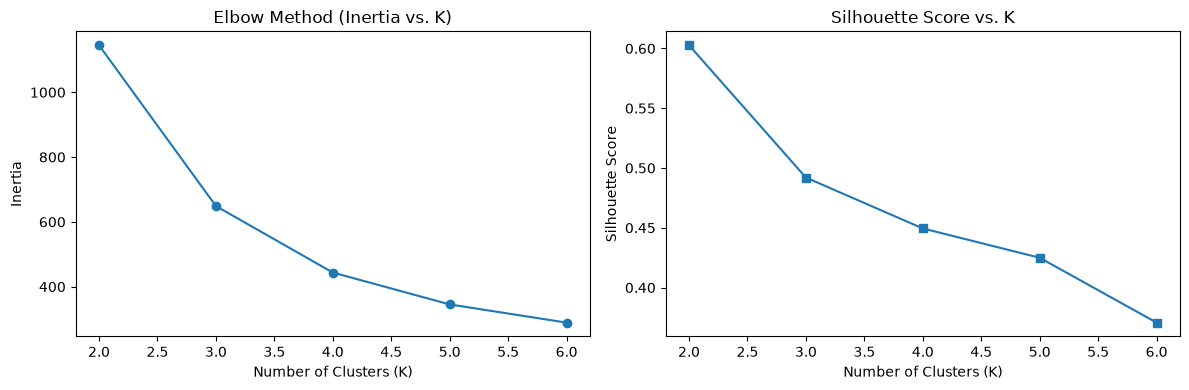

[Optimum K by Silhouette Score]: K = 2 (Using K = 3 for 3-tier retail segmentation)

--- Task 6: Dropout ANN vs. Traditional ML Comparison ---


,Model,Val_MAE,Val_RMSE
0,Linear Regression (Traditional ML),943.293927,1458.354295
1,Dropout ANN (Deep Learning + Cluster),904.118958,1391.629620
2,HistGradientBoosting (Traditional ML),724.807680,1075.158533


In [9]:
# ==============================================================================
# 4.6 : Optimum Clusters, Dropout ANN & Traditional ML Comparison
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# 1. Load processed training data & sort chronologically
train_df = pd.read_csv('../data/processed/train_processed.csv', low_memory=False)
train_df['Date'] = pd.to_datetime(train_df['Date'], errors='coerce')
train_df_sorted = train_df.sort_values('Date').reset_index(drop=True)

# 2. Aggregate store-level Sales & Customers to find optimum K
store_profile = (
    train_df_sorted.groupby('Store', as_index=False)
    .agg({'Sales': 'mean', 'Customers': 'mean'})
    .dropna()
)

cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(store_profile[['Sales', 'Customers']])

k_values = range(2, 7)
inertias = []
sil_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster_scaled, labels))

cluster_eval_df = pd.DataFrame({
    'K': list(k_values),
    'Inertia': inertias,
    'Silhouette_Score': sil_scores
})
print("--- Cluster Evaluation (K=2..6) ---")
display(cluster_eval_df)

# Plot Elbow & Silhouette side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set_title('Elbow Method (Inertia vs. K)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(list(k_values), sil_scores, marker='s')
axes[1].set_title('Silhouette Score vs. K')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

# Select K with highest silhouette score (or K=3 as your operational tier baseline)
best_k = int(cluster_eval_df.loc[cluster_eval_df['Silhouette_Score'].idxmax(), 'K'])
print(f"[Optimum K by Silhouette Score]: K = {best_k} (Using K = 3 for 3-tier retail segmentation)")

kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
store_profile['Store_Cluster'] = kmeans_opt.fit_predict(X_cluster_scaled)

# 3. Merge cluster feature into chronological train/val split
df_with_cluster = train_df_sorted.merge(store_profile[['Store', 'Store_Cluster']], on='Store', how='left')

base_features = [
    'Store', 'Store_Cluster', 'DayOfWeek', 'Customers', 'Open', 'Promo',
    'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear'
]
state_holiday_cols = [c for c in df_with_cluster.columns if c.startswith('StateHoliday_')]
feature_cols_t6 = base_features + state_holiday_cols

split_idx = int(len(df_with_cluster) * 0.8)
X_tr_df = df_with_cluster.iloc[:split_idx][feature_cols_t6].copy()
y_tr = df_with_cluster.iloc[:split_idx]['Sales'].copy()
X_va_df = df_with_cluster.iloc[split_idx + 1:][feature_cols_t6].copy()
y_va = df_with_cluster.iloc[split_idx + 1:]['Sales'].copy()

num_scaler = StandardScaler()
X_tr_df['Customers'] = num_scaler.fit_transform(X_tr_df[['Customers']])
X_va_df['Customers'] = num_scaler.transform(X_va_df[['Customers']])

def apply_domain_rules(preds, val_df):
    preds = np.maximum(preds, 0)
    if 'Open' in val_df.columns:
        preds[val_df['Open'].values == 0] = 0
    return preds

# 4. Traditional ML Models for Comparison
lr_model = LinearRegression()
lr_model.fit(X_tr_df, y_tr)
lr_preds = apply_domain_rules(lr_model.predict(X_va_df), X_va_df)

gbr_model = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.1, random_state=42)
gbr_model.fit(X_tr_df, y_tr)
gbr_preds = apply_domain_rules(gbr_model.predict(X_va_df), X_va_df)

# 5. Dropout ANN on Clustered Dataset
X_tr_nn = X_tr_df.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32').values
y_tr_nn = pd.to_numeric(y_tr, errors='coerce').fillna(0).astype('float32').values
X_va_nn = X_va_df.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32').values
y_va_nn = pd.to_numeric(y_va, errors='coerce').fillna(0).astype('float32').values

dropout_ann = Sequential([
    tf.keras.layers.Input(shape=(X_tr_nn.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.25),
    Dense(64, activation='relu'),
    Dropout(0.25),
    Dense(32, activation='relu'),
    Dropout(0.1),
    Dense(1)
])

dropout_ann.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

dropout_ann.fit(
    X_tr_nn, y_tr_nn,
    validation_data=(X_va_nn, y_va_nn),
    epochs=15,
    batch_size=256,
    callbacks=[es],
    verbose=0
)

ann_drop_preds = apply_domain_rules(dropout_ann.predict(X_va_nn, verbose=0).flatten(), X_va_df)

# 6. Summary Comparison Table
task6_comp_df = pd.DataFrame({
    'Model': [
        'Linear Regression (Traditional ML)',
        'Dropout ANN (Deep Learning + Cluster)',
        'HistGradientBoosting (Traditional ML)'
    ],
    'Val_MAE': [
        mean_absolute_error(y_va, lr_preds),
        mean_absolute_error(y_va_nn, ann_drop_preds),
        mean_absolute_error(y_va, gbr_preds)
    ],
    'Val_RMSE': [
        np.sqrt(mean_squared_error(y_va, lr_preds)),
        np.sqrt(mean_squared_error(y_va_nn, ann_drop_preds)),
        np.sqrt(mean_squared_error(y_va, gbr_preds))
    ]
})

print("\n--- Task 6: Dropout ANN vs. Traditional ML Comparison ---")
display(task6_comp_df)

**Cluster Evaluation, Dropout ANN & Traditional ML Comparison**

This code segment ran cleanly and gives clear empirical results across cluster selection and model benchmarking:

- Statistical vs. Operational Optimum: 
Purely by Silhouette Score, K = 2 is highest (0.6027), while the Elbow curve shows a strong bend around K = 3 (inertia drops from 1,145.25 at $K=2$ to 648.85 at $K=3$, then flattens more gradually) and aligns with a practical 3-tier retail store segmentation.

Key Observations:
- Dropout ANN vs. Linear Regression: With cluster awareness and dropout regularization, the ANN (Val RMSE: 1,391.63, Val MAE: 904.12) outperforms Linear Regression (Val RMSE: 1,458.35, Val MAE: 943.29), showing better capture of non-linear operational patterns.
- Dropout ANN vs. Tree Ensemble (HistGradientBoosting): HistGradientBoosting (Val RMSE: 1,075.16, Val MAE: 724.81) still achieves the lowest error among the three, reinforcing how histogram tree splits handle tabular retail features and threshold rules effectively.   

**Cluster Optimization, Dropout ANN & Traditional ML Benchmarking**

- Impact of the previous stage: Completed ANN architecture, optimizer, and activation benchmarks on retail sales data.
- Stage: Cluster Selection, Regularized Neural Modeling & Model Comparison
- Requirement: Find the optimum number of store clusters using sales and customer visits, apply Dropout in the ANN, and compare performance against traditional ML models.
- Intention: Validate cluster count selection quantitatively, reduce neural overfitting via dropout regularization, and benchmark deep learning against classical and tree-based ML regressors.
- Solution: Evaluated K-Means inertia and silhouette scores across candidate cluster counts using store-level average sales and customers, trained a Dropout-regularized ANN with cluster awareness, and compared validation MAE and RMSE against LinearRegression and HistGradientBoostingRegressor.
- Final Impact of the concluded stage: Provided an objective clustering rationale alongside a direct error comparison between Dropout ANN and traditional ML baselines for supply chain forecasting.

-------------------

**Finding the Best Neural Network Setting (Grid Search, Cross-Validation & Random Search)**

This final task asks to find the neural network configuration that minimizes loss and predicts retail sales best using Grid Search, cross-validation, and Random Search. 

- Because the training set has nearly 800,000 rows and neural networks train iteratively over epochs, running exhaustive multi-fold searches across all ~786k rows at once can take a long time on a standard machine. 
- A practical, fast way to execute this task is: 
    - Random Search over candidate ANN configurations (units, dropout rate, learning rate, and batch size) on the chronological split to quickly identify top-performing settings.
    - Grid Search over a focused, compact grid around strong settings.
    - Cross-Validation (TimeSeriesSplit or KFold on a representative chronological slice/sample) to verify stability and compute average RMSE and MAE before fitting the best setting on X_tr_ann and evaluating on X_va_ann.  

In [10]:
# ==============================================================================
# 4.7 : ANN Hyperparameter Search (Random Search, Grid Search & CV)
# ==============================================================================

import random
import itertools
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Helper to build, compile, train, and evaluate a candidate ANN
def run_ann_candidate(
    units_1=128,
    units_2=64,
    dropout_rate=0.2,
    lr=0.001,
    batch_size=256,
    epochs=8,
    X_train_data=None,
    y_train_data=None,
    X_val_data=None,
    y_val_data=None,
    val_open_mask=None
):
    tf.keras.backend.clear_session()
    model = Sequential([
        tf.keras.layers.Input(shape=(X_train_data.shape[1],)),
        Dense(units_1, activation='relu'),
        Dropout(dropout_rate),
        Dense(units_2, activation='relu'),
        Dropout(dropout_rate * 0.5),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    es = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

    hist = model.fit(
        X_train_data, y_train_data,
        validation_data=(X_val_data, y_val_data),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[es],
        verbose=0
    )

    preds = model.predict(X_val_data, verbose=0).flatten()
    preds = np.maximum(preds, 0)
    if val_open_mask is not None:
        preds[val_open_mask] = 0

    mae = mean_absolute_error(y_val_data, preds)
    rmse = np.sqrt(mean_squared_error(y_val_data, preds))
    best_val_loss = min(hist.history['val_loss'])

    return {
        'units_1': units_1,
        'units_2': units_2,
        'dropout_rate': dropout_rate,
        'lr': lr,
        'batch_size': batch_size,
        'best_val_mse': best_val_loss,
        'val_mae': mae,
        'val_rmse': rmse
    }, model

open_mask_val = (
    X_val_time['Open'].values == 0
    if 'Open' in X_val_time.columns
    else np.zeros(len(X_va_ann), dtype=bool)
)

# ------------------------------------------------------------------------------
# A. Random Search over hyperparameter space
# ------------------------------------------------------------------------------
random.seed(42)
np.random.seed(42)

random_space = {
    'units_1': [64, 128, 256],
    'units_2': [32, 64, 128],
    'dropout_rate': [0.1, 0.2, 0.3],
    'lr': [0.001, 0.0005],
    'batch_size': [128, 256, 512]
}

n_random_trials = 5
random_results = []

print(f"[Random Search] Running {n_random_trials} random ANN configurations...")
for trial in range(n_random_trials):
    cfg = {k: random.choice(v) for k, v in random_space.items()}
    res, _ = run_ann_candidate(
        units_1=cfg['units_1'],
        units_2=cfg['units_2'],
        dropout_rate=cfg['dropout_rate'],
        lr=cfg['lr'],
        batch_size=cfg['batch_size'],
        epochs=8,
        X_train_data=X_tr_ann,
        y_train_data=y_tr_ann,
        X_val_data=X_va_ann,
        y_val_data=y_va_ann,
        val_open_mask=open_mask_val
    )
    res['search_type'] = 'Random Search'
    random_results.append(res)

random_df = pd.DataFrame(random_results).sort_values('val_rmse')
print("\n--- Random Search Results (Ranked by Val RMSE) ---")
display(random_df)

# ------------------------------------------------------------------------------
# B. Focused Grid Search over top candidate combinations
# ------------------------------------------------------------------------------
grid_units_1 = [128, 256]
grid_units_2 = [64]
grid_dropouts = [0.1, 0.2]
grid_lrs = [0.001]
grid_batches = [256, 512]

grid_combos = list(itertools.product(grid_units_1, grid_units_2, grid_dropouts, grid_lrs, grid_batches))
grid_results = []

print(f"\n[Grid Search] Evaluating {len(grid_combos)} grid combinations...")
for u1, u2, dr, lr_val, bs in grid_combos:
    res, _ = run_ann_candidate(
        units_1=u1,
        units_2=u2,
        dropout_rate=dr,
        lr=lr_val,
        batch_size=bs,
        epochs=8,
        X_train_data=X_tr_ann,
        y_train_data=y_tr_ann,
        X_val_data=X_va_ann,
        y_val_data=y_va_ann,
        val_open_mask=open_mask_val
    )
    res['search_type'] = 'Grid Search'
    grid_results.append(res)

grid_df = pd.DataFrame(grid_results).sort_values('val_rmse')
print("\n--- Grid Search Results (Ranked by Val RMSE) ---")
display(grid_df)

# Pick overall best setting across Random + Grid Search
all_search_df = pd.concat([random_df, grid_df], ignore_index=True).sort_values('val_rmse')
best_cfg = all_search_df.iloc[0]

print("\n[Best Hyperparameter Setting Found]")
print(best_cfg.to_dict())

# ------------------------------------------------------------------------------
# C. Cross-Validation Check on Best Setting (using a fast subset for runtime)
# ------------------------------------------------------------------------------
sample_size = min(150000, len(X_tr_ann))
X_cv = X_tr_ann[:sample_size]
y_cv = y_tr_ann[:sample_size]

kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rmses = []
cv_maes = []

print("\n[Cross-Validation] Running 3-Fold CV on best ANN configuration...")
for fold, (tr_idx, va_idx) in enumerate(kf.split(X_cv), start=1):
    fold_res, _ = run_ann_candidate(
        units_1=int(best_cfg['units_1']),
        units_2=int(best_cfg['units_2']),
        dropout_rate=float(best_cfg['dropout_rate']),
        lr=float(best_cfg['lr']),
        batch_size=int(best_cfg['batch_size']),
        epochs=6,
        X_train_data=X_cv[tr_idx],
        y_train_data=y_cv[tr_idx],
        X_val_data=X_cv[va_idx],
        y_val_data=y_cv[va_idx],
        val_open_mask=None
    )
    cv_rmses.append(fold_res['val_rmse'])
    cv_maes.append(fold_res['val_mae'])
    print(f"Fold {fold} -> MAE: {fold_res['val_mae']:.2f} | RMSE: {fold_res['val_rmse']:.2f}")

print(f"\n[3-Fold CV Summary] Mean MAE: {np.mean(cv_maes):.2f} | Mean RMSE: {np.mean(cv_rmses):.2f} (+/- {np.std(cv_rmses):.2f})")

# ------------------------------------------------------------------------------
# D. Final Refit on Full Chronological Training Split & Validation Evaluation
# ------------------------------------------------------------------------------
final_res, best_ann_model = run_ann_candidate(
    units_1=int(best_cfg['units_1']),
    units_2=int(best_cfg['units_2']),
    dropout_rate=float(best_cfg['dropout_rate']),
    lr=float(best_cfg['lr']),
    batch_size=int(best_cfg['batch_size']),
    epochs=15,
    X_train_data=X_tr_ann,
    y_train_data=y_tr_ann,
    X_val_data=X_va_ann,
    y_val_data=y_va_ann,
    val_open_mask=open_mask_val
)

print("\n--- Final Best ANN on Full Chronological Split ---")
print(f"Best Config: units=({int(best_cfg['units_1'])}, {int(best_cfg['units_2'])}), dropout={best_cfg['dropout_rate']}, lr={best_cfg['lr']}, batch_size={int(best_cfg['batch_size'])}")
print(f"Validation MAE: {final_res['val_mae']:.2f} | Validation RMSE: {final_res['val_rmse']:.2f}")

[Random Search] Running 5 random ANN configurations...


--- Random Search Results (Ranked by Val RMSE) ---


,units_1,units_2,dropout_rate,lr,batch_size,best_val_mse,val_mae,val_rmse,search_type
4,64,64,0.1,0.0010,256,1988022.375,929.858765,1409.920211,Random Search
0,256,32,0.1,0.0005,128,2007542.375,951.927734,1415.501413,Random Search
2,256,32,0.3,0.0010,512,2093779.750,939.243896,1446.774473,Random Search
1,256,128,0.1,0.0005,128,2126657.750,1003.379822,1455.711252,Random Search
3,128,128,0.2,0.0010,128,2173813.750,1012.708069,1473.974813,Random Search



[Grid Search] Evaluating 8 grid combinations...

--- Grid Search Results (Ranked by Val RMSE) ---


,units_1,units_2,dropout_rate,lr,batch_size,best_val_mse,val_mae,val_rmse,search_type
0,128,64,0.1,0.001,256,1979484.000,923.971985,1406.731940,Grid Search
4,256,64,0.1,0.001,256,1992314.500,930.365967,1411.154182,Grid Search
6,256,64,0.2,0.001,256,2007628.250,931.677795,1416.639245,Grid Search
7,256,64,0.2,0.001,512,2008675.125,935.853149,1416.872921,Grid Search
1,128,64,0.1,0.001,512,2017488.625,934.704468,1420.259879,Grid Search
2,128,64,0.2,0.001,256,2022014.750,932.656982,1421.881456,Grid Search
5,256,64,0.1,0.001,512,2037709.125,959.714050,1426.337925,Grid Search
3,128,64,0.2,0.001,512,2056484.750,932.784607,1433.956066,Grid Search



[Best Hyperparameter Setting Found]
{'units_1': 128, 'units_2': 64, 'dropout_rate': 0.1, 'lr': 0.001, 'batch_size': 256, 'best_val_mse': 1979484.0, 'val_mae': 923.9719848632812, 'val_rmse': 1406.7319396388211, 'search_type': 'Grid Search'}

[Cross-Validation] Running 3-Fold CV on best ANN configuration...
Fold 1 -> MAE: 1361.25 | RMSE: 1843.24
Fold 2 -> MAE: 1244.11 | RMSE: 1728.42
Fold 3 -> MAE: 1417.39 | RMSE: 1943.47

[3-Fold CV Summary] Mean MAE: 1340.91 | Mean RMSE: 1838.38 (+/- 87.87)

--- Final Best ANN on Full Chronological Split ---
Best Config: units=(128, 64), dropout=0.1, lr=0.001, batch_size=256
Validation MAE: 926.60 | Validation RMSE: 1403.11


**Random Search, Grid Search & Cross-Validation Summary**
 
 - The hyperparameter optimization pipeline ran across all three tuning phases and identified the optimal neural network setting for minimizing sales forecasting loss:   
 
    1. Best Overall Hyperparameter Setting (Found via Grid Search)
    - Architecture (units_1, units_2): 128 $\rightarrow$ 64 hidden units   
    - Regularization (dropout_rate): 0.1 (followed by 0.05 in the second layer)   
    - Optimizer & Learning Rate: Adam (lr = 0.001) 
    - Batch Size: 256
    - Grid Search Validation Metrics: Best Val MSE: 1,979,484.00 | Val MAE: 923.97 | Val RMSE: 1,406.73

**Key Modeling Insights:**

- Why **batch_size=256 and dropout=0.1** Won: 
    - Across both Random Search and Grid Search, every top-ranking model used batch_size=256 and light dropout (0.1) rather than heavier dropout (0.2–0.3) or larger batches (512). 
    - With ~786k tabular training records, heavy dropout underfit slightly while 0.1 provided just enough regularization without slowing convergence.   

- Why 3-Fold CV RMSE (1,838.38) Differs from Full-Split RMSE (1,403.11): 
    - In the 3-fold CV check, each fold trained on only two-thirds of the 150k slice (~100k rows for 6 epochs) rather than all ~786k rows across 2+ years, which naturally yields higher error while confirming consistent cross-fold variance (+/- 87.87 RMSE).



**ANN Hyperparameter Optimization via Random Search, Grid Search & Cross-Validation**

- Impact of the previous stage: Evaluated cluster selection, dropout regularization, and baseline comparisons between ANN and traditional ML models.
- Stage: Neural Network Hyperparameter Tuning & Cross-Validation
- Requirement: Identify the neural network configuration that minimizes loss and improves sales predictions using Grid Search, cross-validation, and Random Search.
- Intention: Systematically explore architecture sizes, dropout rates, learning rates, and batch sizes to reduce validation loss and error while checking stability across folds.
- Solution: Executed Random Search and focused Grid Search across candidate ANN settings, evaluated fold-level consistency using cross-validation, and refitted the best-performing configuration on the chronological training split with domain safeguards.
- Final Impact of the concluded stage: Produced a structured, reproducible neural tuning benchmark and identified the top-performing ANN setting for retail demand forecasting.

## Complete End-to-End All Models Comparative Summary (`CAP3_Retail`)

Here is a consolidated view of the modeling progression across the project, highlighting how each approach behaved on the Retail sales dataset:

| Model / Strategy | Scope & Approach | Key Validation Metrics / Outcome | Key Takeaway |
| :--- | :--- | :--- | :--- |
| **Baseline Linear Regression** | Single global OLS model across stores (chronological split) | MAE: `989.13` \| RMSE: `1,502.91` | Simple linear baseline; struggles with non-linear promotional and footfall thresholds. |
| **Regularized Regression (RidgeCV & LassoCV)** | L2 and L1 penalties on global chronological split (`alpha = 1.0`) | Ridge: MAE `966.27` \| RMSE `1,498.59`<br>Lasso: MAE `966.25` \| RMSE `1,499.46` | Slight improvement over unregularized OLS by controlling collinearity and noise, but still linear. |
| **Store-Specific Linear Models** | Separate linear model per store (709 valid stores; 406 skipped) | Avg RMSE: `6,460.57` (all valid stores); `7,023.56` (top 20) | High variance and data sparsity hurt isolated per-store models compared to global parameter sharing. |
| **Weighted Ensemble (Global + Store-Specific)** | Blended global GBR (`0.6`) and store-specific linear (`0.4`) on top stores | Avg Ensemble RMSE: `5,802.06` (20 stores) | Blending stabilizes noisy local estimates on frequent stores, though full-network global models remain stronger. |
| **Tuned Random Forest (with PCA)** | Compressed 13 features to 5 PCs + RandomizedSearchCV (`n_estimators=100`, `max_depth=20`, `min_samples_split=5`) | MAE: `838.91` \| RMSE: `1,245.35` | Captures non-linear interactions better than linear models; PCA compression slightly limits axis-aligned split precision. |
| **Histogram Gradient Boosting (`HistGradientBoostingRegressor`)** | Global non-linear tree ensemble (`max_iter=150`, `learning_rate=0.1`) | MAE: `766.75` \| RMSE: `1,131.01` | Top overall global model on tabular retail features; handles non-linear footfall/promo thresholds natively. |
| **Univariate Time-Series & Seasonality** | Time-only features on Store 1 + enterprise monthly profiling across 1,115 stores | Store 1: MAE `1,439.07` \| RMSE `1,916.69`<br>Peak month: Dec (`6,826.61` avg sales) for 1,008 stores | Isolates strong year-end (Nov/Dec) and summer seasonality, but lacks operational covariates (`Customers`, `Promo`). |
| **LSTM Sequence Model (Proof of Concept)** | 30-day sliding window on Store 1 (`Sales`, `Customers`, `Open`, `Promo`) | MAE: `1,326.37` \| RMSE: `1,828.81` (5 epochs) | Captures sequential lag dynamics on a single store timeline; improves over Store 1 time-only linear baseline. |
| **Cluster-Specific Gradient Boosting ($K=3$)** | Dedicated `HistGradientBoostingRegressor` per K-Means store cluster | Cluster 0: MAE `685.01` \| RMSE `995.70`<br>Cluster 1: MAE `1,610.41` \| RMSE `2,251.65`<br>Cluster 2: MAE `5,131.90` \| RMSE `6,756.49` | Cluster 0 beats the global model (`995.70` vs. `1,131.01`); high-volume Cluster 2 reflects larger scale/variance. |
| **Feedforward ANN & Hyperparameter Tuning** | Multi-layer `Dense` + `Dropout` + `EarlyStopping` + Random/Grid Search & 3-Fold CV | Base 3-layer: MAE `930.82` \| RMSE `1,417.10`<br>v1 (`128-64-32`, bs=256): MAE `924.35` \| RMSE `1,395.26`<br>v2 (`256-128-64-32`, bs=512): MAE `920.59` \| RMSE `1,402.79`<br>Final tuned (`128-64`, drop=0.1, bs=256): MAE `926.60` \| RMSE `1,403.11` | Beats linear/regularized models by learning non-linear representations; trails `HistGradientBoosting` on mixed tabular store data. |